# 지금까지 만든 모델 전체 정리 — TEP와 PHM 2018

**모델이 어떤 문제를 풀고, 무엇을 비교했으며, 어느 결과까지 믿을 수 있는지**를 한 파일에 정리했습니다. 확인 범위는 로컬 TEP, PHM2018-Project(V1), V2, V3 및 V1 재분석 폴더입니다. 다른 프로젝트(SRAM·WM811K 등)는 이번 범위에 포함하지 않았습니다.

TEP는 **고장 주입 후 검출·유형 진단**, PHM은 **기록된 고장 정지 이전 조기 예측**, 새 TEP LSTM은 **다음 시점 센서값 회귀**입니다. 과제가 다르므로 Accuracy나 검출률로 서로 순위를 매기지 않습니다.

기준일: 2026-11-12. 원본 데이터·기존 모델·노트북을 변경하지 않았습니다. 기존 평가표와 저장 예측을 읽었으며 **새 학습·새 모델 추론·임계값 선택은 하지 않았습니다.** PHM은 읽기 전용으로 확인했습니다.

아래 표·그림은 **내장 스냅샷**으로 표시됩니다. 다른 폴더로 옮겨도 기존 출력으로 열람할 수 있고, Python·pandas·NumPy·matplotlib·IPython 환경에서 원 프로젝트 없이 재실행할 수 있습니다. 내장 자료는 원 센서 데이터나 모델 바이너리를 포함하지 않습니다.

In [1]:
import base64, zlib, json, io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
pd.set_option('display.max_rows', 90)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'font.family':'Malgun Gothic','axes.unicode_minus':False,'figure.dpi':120})
PAYLOAD = '...'

snapshot=json.loads(zlib.decompress(base64.b64decode(PAYLOAD)).decode('utf-8'))
T={k:pd.read_csv(io.StringIO(s)) for k,s in snapshot['tables'].items()}
E=snapshot['extra']
def show(key,columns=None):
    frame=T[key] if columns is None else T[key][columns]
    display(frame.style.hide(axis='index'))
def picture(key):display(Image(data=base64.b64decode(snapshot['images'][key])))
display(Markdown('**내장 평가 결과 준비 완료 — 모델을 학습하거나 추론하지 않습니다.**'))

**내장 평가 결과 준비 완료 — 모델을 학습하거나 추론하지 않습니다.**

## 1. 먼저 보는 전체 모델 지도

‘모델 종류’, ‘학습 실행 수’, ‘평가 행 수’는 다릅니다. 같은 XGBoost를 특징·seed·분할별로 학습하면 여러 실행이 됩니다. 임계값만 달리 평가한 것은 새 학습 모델로 세지 않습니다. 아래는 기준선을 포함한 역할별 목록입니다.

In [2]:
show('model_catalog')

프로젝트,모델/기준선,목표,역할,입력,특징/상태
TEP,Logistic Regression,21종 분류,선형 기준선,현재 52 / 통계 312,Validation 구성·임계값 선택
TEP,Random Forest,21종 분류,비선형 트리 앙상블,현재 52 / 통계 312,가중치 구성 비교
TEP,XGBoost,21종 분류,부스팅 트리,현재 52 / 통계 312,현재값과 과거 통계 비교
TEP,LSTM 분류기,21종 분류,순환 시계열 모델,20×52,후속 LSTM 회귀기와 별개
TEP,GRU 분류기,21종 분류,게이트 순환 모델,20×52,CNN과 동일 분할로 비교
TEP,1D-CNN,21종 분류·이상 검출,선택된 주 모델,20×52,seed42 고정; 유형·지연 추가 평가
TEP,Binary XGBoost,정상/고장 2종,별도 이진 기준선,통계 312,natural/balanced/under/oversample
TEP,Unknown Binary XGBoost,미지 고장 검출 연구,Fault 3·9·15를 학습에서 제외,통계 312,미지/기지 평가 분리
TEP,LSTM 회귀기,다음 3분 52변수 예측,별도 새 예측기,20×52 → 52,정상만 학습; CNN 연결 없음
TEP,Persistence,다음값 예측 기준선,다음값=현재값,현재 52,학습 없는 회귀 비교 기준


## 2. 프로젝트별 연구 진행과 실험 규모

PHM V1 README의 초기 EDA 상태보다 후속 4·4.5단계 보고서와 실제 결과표를 우선했습니다. V1 `reanalysis_v2`는 계획·폴더만 있고 학습 산출물은 확인되지 않았습니다. PHM V2도 학습 모델이 없습니다. **누락된 성능을 0으로 채우지 않았습니다.**

In [3]:
coverage=pd.DataFrame([
 ['TEP Phase2',len(T['tep_test']),'공통 Test 평가 model_id 수; seed·구성 변형 포함'],
 ['TEP 별도 LSTM 예측',len(T['forecast_train']),'학습 seed 수; Persistence는 학습하지 않음'],
 ['PHM V1 stage4',len(T['v1_metrics'].query("split == 'evaluation'")),'48개 본/확장 + 10개 ID 보조진단; 단순 기준선 포함'],
 ['PHM V1 stage4.5',E['v1_cv_summary']['experiments'],'4-Fold × 4설정; 정책 2개 평가이므로 성능표 32행'],
 ['PHM V2',0,'감사·대표 2대 후보 생성; 학습 없음'],
 ['PHM V3 stage2',len(T['phm_stage2_train']),'A/B × Logistic/XGBoost 최대가용 코호트'],
 ['PHM V3 stage3',len(T['phm_stage3_train']),'A/B/C × Logistic/XGBoost 공통 코호트'],
 ['PHM V3 stage4',len(T['phm_stage4_train']),'21개 보존 실행 중 신규 18개·stage3 재사용 3개'],
 ['PHM V3 stage5',len(T['phm_stage5_train']),'보호된 장비 그룹 검증용 XGBoost'],
 ['PHM V3 stage6',0,'기존 stage2 B를 동결; 새 학습 없이 최종 Holdout 1회'],
 ['PHM V3 stage7',len(T['phm_stage7_train']),'03M02 장비 전용 신규 학습 1개']
],columns=['단계','실행/모델 수','분모 및 의미'])
display(coverage.style.hide(axis='index'))

단계,실행/모델 수,분모 및 의미
TEP Phase2,44,공통 Test 평가 model_id 수; seed·구성 변형 포함
TEP 별도 LSTM 예측,3,학습 seed 수; Persistence는 학습하지 않음
PHM V1 stage4,58,48개 본/확장 + 10개 ID 보조진단; 단순 기준선 포함
PHM V1 stage4.5,16,4-Fold × 4설정; 정책 2개 평가이므로 성능표 32행
PHM V2,0,감사·대표 2대 후보 생성; 학습 없음
PHM V3 stage2,4,A/B × Logistic/XGBoost 최대가용 코호트
PHM V3 stage3,6,A/B/C × Logistic/XGBoost 공통 코호트
PHM V3 stage4,21,21개 보존 실행 중 신규 18개·stage3 재사용 3개
PHM V3 stage5,6,보호된 장비 그룹 검증용 XGBoost
PHM V3 stage6,0,기존 stage2 B를 동결; 새 학습 없이 최종 Holdout 1회


## 3. 지표를 읽는 공통 기준

| 지표 | 질문 | 주의점 |
|---|---|---|
| Accuracy | 시점별 정답을 얼마나 맞혔나? | 정상 비중이 높으면 고장을 전부 놓쳐도 높음 |
| Precision / Recall / F1 | 경보의 정확성과 고장 포착이 어떤가? | 임계값과 평가 라벨 집합을 확인 |
| Macro-F1 | 각 클래스의 F1을 동등하게 평균하면? | 고장 유형 불균형을 보완 |
| ROC-AUC / AP | 점수의 순위 구분 능력은? | 임계값 적용 Accuracy와 다름; AP는 양성 비율 영향 |
| 전체 이벤트 검출률 | 기록된 전체 고장을 얼마나 검출했나? | 입력 없는 고장도 분모에 포함 |
| 조건부 이벤트 검출률 | 입력이 있었던 고장 중 얼마나 검출했나? | 입력 부족으로 평가 불가한 사건을 숨길 수 있음 |
| 지연 / 선행시간 | 고장 후 얼마나 늦게 / 고장 전 얼마나 일찍? | 성공한 사건만의 통계인지 확인 |
| RMSE / MAE | 연속값 예측 오차는? | LSTM 센서 예측에 사용; 분류 Accuracy를 적용하지 않음 |

이번에 추가 계산한 Accuracy는 저장 혼동행렬 또는 저장 예측·고정 임계값으로 계산했습니다. 이미 보고된 원 지표와 구분해 설명합니다. PHM V1은 당시 보고서가 초 해석을 지지했지만 V3는 raw 단위를 유지합니다. 통합 비교에서는 PHM 시간을 임의로 분/시간으로 변환하지 않습니다.

## 4. TEP — 모델 구성과 비교 조건

Harvard TEP, 52변수, 3분 간격, 실행 family 기준 Train400 / Validation100 / 공식 Test500 분할입니다. 현재 특징은52개, 통계 특징은312개, 시계열 특징은20×52입니다. 같은 run family의 정상·고장 시나리오를 같은 분할에 두었습니다.

Logistic/RF/XGBoost의 현재·통계 특징과 class weight를 비교했고, LSTM·GRU·CNN은 같은 시계열 입력으로 비교했습니다. Binary XGBoost는 정상/고장 전용이며 Unknown Binary는 Fault 3·9·15를 학습에서 제외한 별도 실험입니다. 주 CNN은 Validation으로 선택한 **seed42 단일 모델**이며 ensemble이 아닙니다.

model,features,weight,2종 Accuracy 평균(%),2종 SD(%p),21종 Accuracy 평균(%),21종 SD(%p),seeds,samples
CNN1D,Temporal,balanced,89.95,0.38,88.12,0.26,3,997500
LSTM,Temporal,balanced,89.69,0.70,87.69,0.67,3,997500
GRU,Temporal,balanced,89.62,0.45,87.51,0.37,3,997500
XGBoost,Statistical,natural,86.09,0.05,84.33,0.04,3,997500
LogisticRegression,Statistical,balanced,84.32,0.00,81.60,0.00,3,997500
RandomForest,Statistical,natural,84.21,0.12,82.09,0.09,3,997500
XGBoost,Current,balanced,79.38,0.21,76.20,0.19,3,997500
RandomForest,Current,natural,73.30,0.34,69.65,0.36,3,997500
LogisticRegression,Current,natural,64.65,0.00,56.71,0.00,3,997500


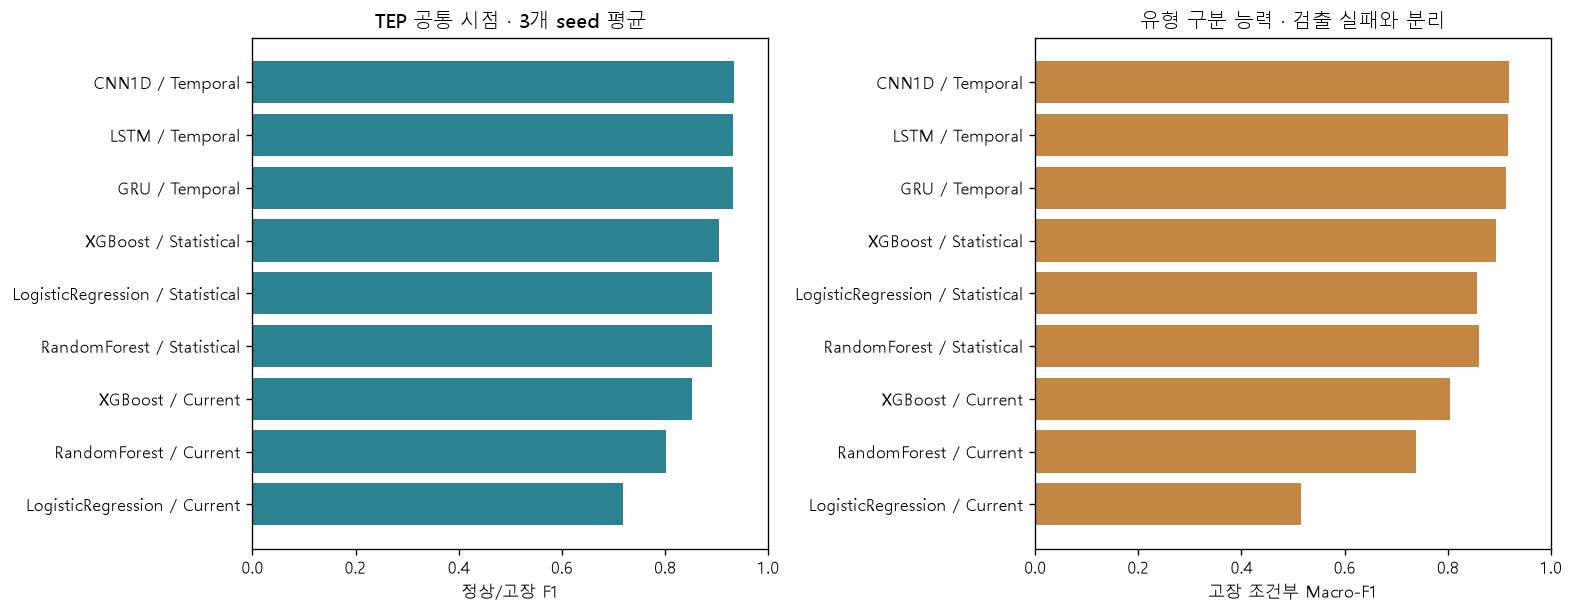

model,features,weight,seeds,detection_f1_mean,diagnosis_macro_f1_mean,end_to_end_macro_f1_mean
CNN1D,Temporal,balanced,3,0.933326,0.917972,0.863193
LSTM,Temporal,balanced,3,0.931497,0.915881,0.860242
GRU,Temporal,balanced,3,0.931007,0.912067,0.857672
XGBoost,Statistical,natural,3,0.905238,0.893980,0.815886
LogisticRegression,Statistical,balanced,3,0.891907,0.855969,0.787105
RandomForest,Statistical,natural,3,0.891010,0.860842,0.793156
XGBoost,Current,balanced,3,0.852931,0.803518,0.737753
RandomForest,Current,natural,3,0.800936,0.737815,0.663424
LogisticRegression,Current,natural,3,0.718295,0.516140,0.470851


In [4]:
a=T['tep_accuracy'].copy()
for c in ['binary_accuracy_mean','binary_accuracy_sd','class21_accuracy_mean','class21_accuracy_sd']:a[c]*=100
display(a.rename(columns={'binary_accuracy_mean':'2종 Accuracy 평균(%)','binary_accuracy_sd':'2종 SD(%p)',
 'class21_accuracy_mean':'21종 Accuracy 평균(%)','class21_accuracy_sd':'21종 SD(%p)'}).style.format(precision=2).hide(axis='index'))
q=T['tep_means']
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
names=q.model+' / '+q.features
axes[0].barh(names,q.detection_f1_mean,color='#2b8291');axes[0].set(xlim=(0,1),xlabel='정상/고장 F1',title='TEP 공통 시점 · 3개 seed 평균')
axes[1].barh(names,q.diagnosis_macro_f1_mean,color='#c48643');axes[1].set(xlim=(0,1),xlabel='고장 조건부 Macro-F1',title='유형 구분 능력 · 검출 실패와 분리')
for ax in axes:ax.invert_yaxis()
plt.show()
show('tep_means',['model','features','weight','seeds','detection_f1_mean','diagnosis_macro_f1_mean','end_to_end_macro_f1_mean'])

### TEP의 별도 이진 탐지와 미지 고장

정상/고장 전용 XGBoost는 natural/balanced/undersample/oversample을 비교했습니다. Unknown Binary의 미학습 고장 성능은 같은 고장 유형을 학습한 CNN의 결과와 같은 조건이 아닙니다. 분류 유형을 출력하지 않는 이진 모델의 21종 Accuracy는 공란입니다.

In [5]:
z=T['tep_all_results']; binary=z[z.model_id.str.contains('BinaryXGBoost')]
display(binary[['model_id','binary_accuracy','detection_f1','detection_roc_auc',
                'unseen_faults_detection_f1','seen_faults_detection_f1']].style.format(precision=4).hide(axis='index'))

model_id,binary_accuracy,detection_f1,detection_roc_auc,unseen_faults_detection_f1,seen_faults_detection_f1
BinaryXGBoost_Statistical_natural_s42,0.8413,0.8905,0.9430,nan,nan
BinaryXGBoost_Statistical_natural_s7,0.8435,0.8922,0.9433,nan,nan
BinaryXGBoost_Statistical_natural_s2026,0.8407,0.8900,0.9434,nan,nan
BinaryXGBoost_Statistical_balanced_s42,0.8485,0.8960,0.9421,nan,nan
BinaryXGBoost_Statistical_balanced_s7,0.8494,0.8967,0.9429,nan,nan
BinaryXGBoost_Statistical_balanced_s2026,0.8489,0.8963,0.9423,nan,nan
BinaryXGBoost_Statistical_undersample_s42,0.8420,0.8909,0.9361,nan,nan
BinaryXGBoost_Statistical_oversample_s42,0.8488,0.8962,0.9434,nan,nan
UnknownBinaryXGBoost_Statistical_balanced_s2026,0.8519,0.8986,0.9374,0.0524,0.9768
UnknownBinaryXGBoost_Statistical_balanced_s42,0.8518,0.8985,0.9377,0.0480,0.9769


### 최종 CNN의 전체 Test 결과와 추가된 기능

공통 비교는997,500시점이고 최종 CNN 전체 평가는9,880,500시점입니다. 평가 시점 차이 때문에 두 표의 점수가 다릅니다. 유형별 진단 평가는 이미 존재한21개 출력을 재사용했으며 새 분류 head를 학습하지 않았습니다. 고정 임계값에서 고장3연속이면 검출, 동일 유형3연속이면 유형 확정입니다.

지표,측정값
정상/고장 Accuracy,89.05%
임계값 적용 21종 Accuracy,87.32%
고장 조건부 20종 Accuracy,91.36%
정상/고장 F1,92.77%
정상/고장 ROC-AUC,95.39%
임계값 적용 21종 Macro-F1,85.58%
실행 검출률,98.51%
실행 정답 유형 진단률,90.15%
최초 확정 유형 정확도,44.85%


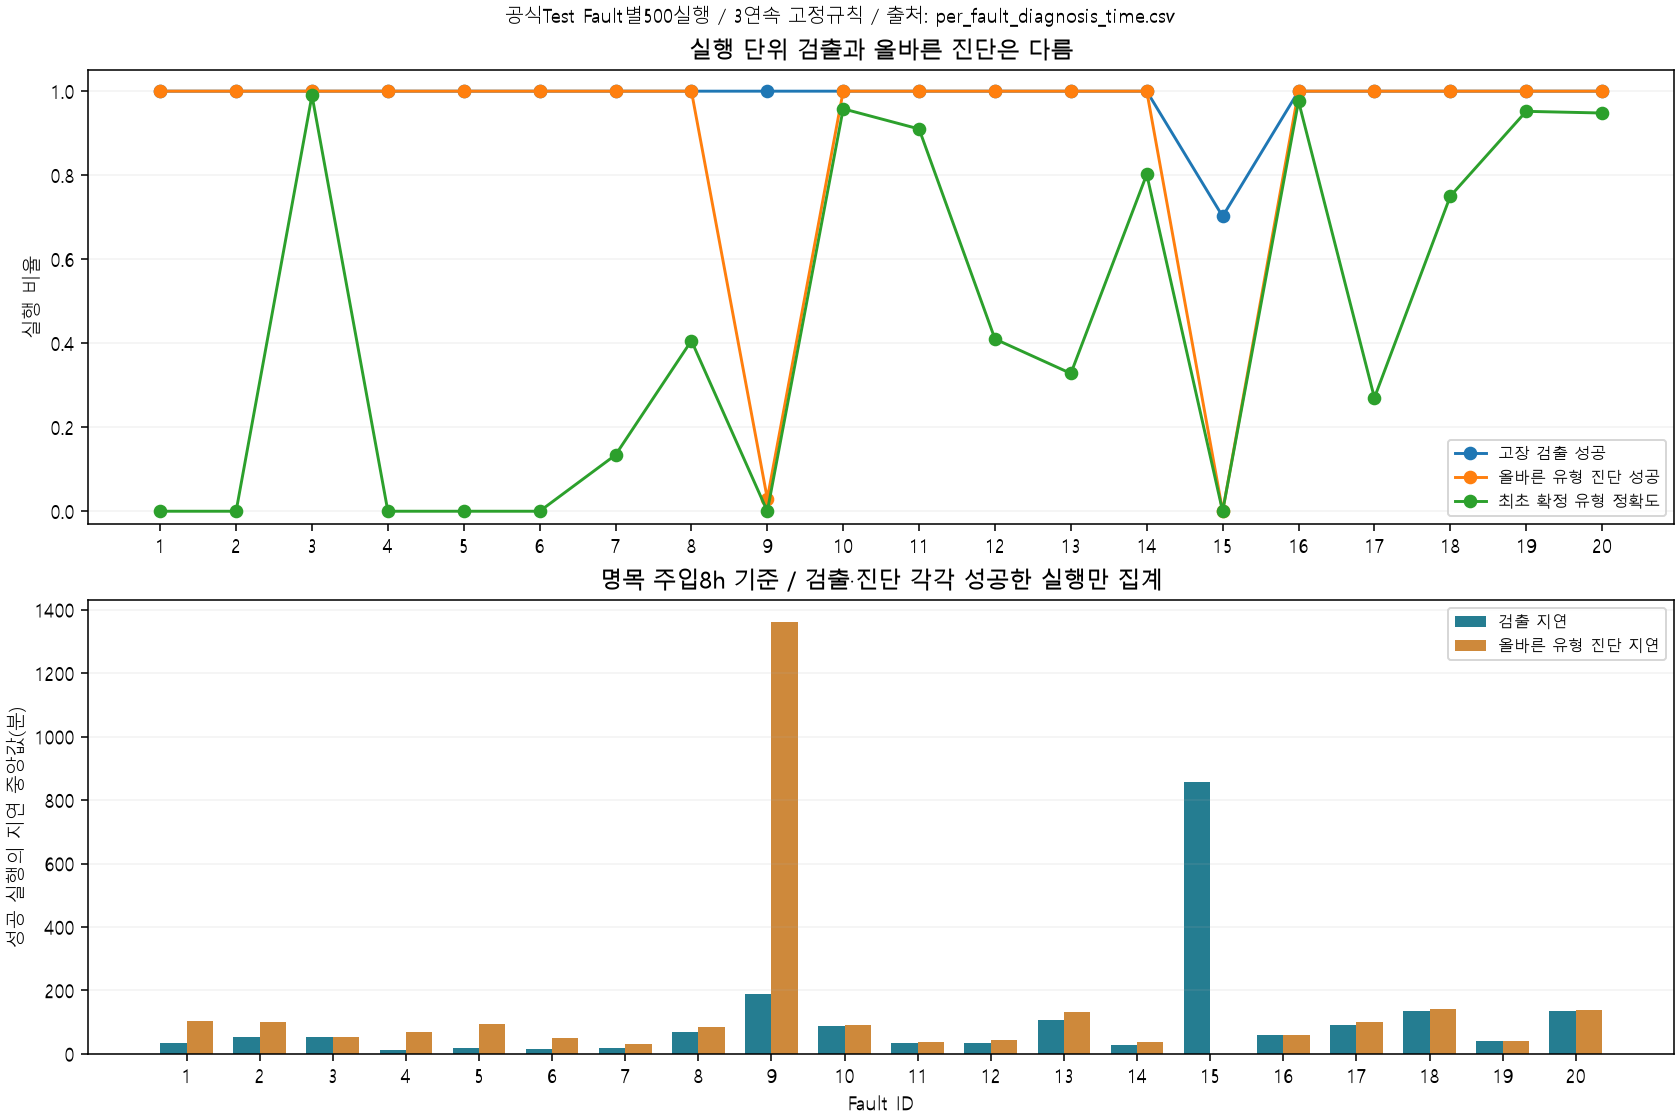

In [6]:
d=E['tep_dense']['joint_primary'];v=E['diagnosis']
display(pd.DataFrame([
 ['정상/고장 Accuracy',E['tep_dense_accuracy']['binary']],['임계값 적용 21종 Accuracy',E['tep_dense_accuracy']['class21']],
 ['고장 조건부 20종 Accuracy',v['classification_metrics']['conditional20']['accuracy']],
 ['정상/고장 F1',d['detection_f1']],['정상/고장 ROC-AUC',d['detection_roc_auc']],
 ['임계값 적용 21종 Macro-F1',d['end_to_end_macro_f1']],
 ['실행 검출률',v['detection_run_rate']],['실행 정답 유형 진단률',v['correct_diagnosis_run_rate']],
 ['최초 확정 유형 정확도',v['first_confirmed_type_accuracy']]
],columns=['지표','측정값']).style.format({'측정값':'{:.2%}'}).hide(axis='index'))
picture('diag')

검출률98.51%와 정답 유형 진단률90.15%는 실행 단위 결과입니다. 최초 확정 유형 정확도44.85%는 최초 유형이 확정된 실행이 분모입니다. Fault9는500실행 중15개만 정답 진단, Fault15는0개였습니다. 검출 지연 중앙48분, 정답 진단 지연 중앙69분은 각각 성공한 실행만의 통계입니다.

## 5. TEP — 입력 가용성 저하와 PHM 취약점 모사

전체 고장 실행 중0/10/25/40/53.1%를 입력 부족으로 평가 불가능하게 만들었습니다. 샘플 삭제율이 아닙니다. 고장별 균형 선정, seed42·43·44 반복, 모델·임계값·라벨은 고정입니다. 유효20시점 창만 남겨 평가하고 임의 예측이나 미래 보간은 하지 않았습니다. 짧은 누락 뒤 유효 입력이 남으면 부분 가용 실행으로 집계했습니다.

rate,available_runs,unavailable_runs,overall_detection_rate,conditional_detection_rate,overall_correct_diagnosis_rate,conditional_correct_diagnosis_rate
0.000000,10000.000000,0.000000,0.985100,0.985100,0.901500,0.901500
0.100000,9000.000000,1000.000000,0.886400,0.984889,0.811400,0.901556
0.250000,7500.000000,2500.000000,0.738300,0.984400,0.676133,0.901511
0.400000,6000.000000,4000.000000,0.590667,0.984444,0.540933,0.901556
0.531000,4690.000000,5310.000000,0.461733,0.984506,0.422867,0.901635


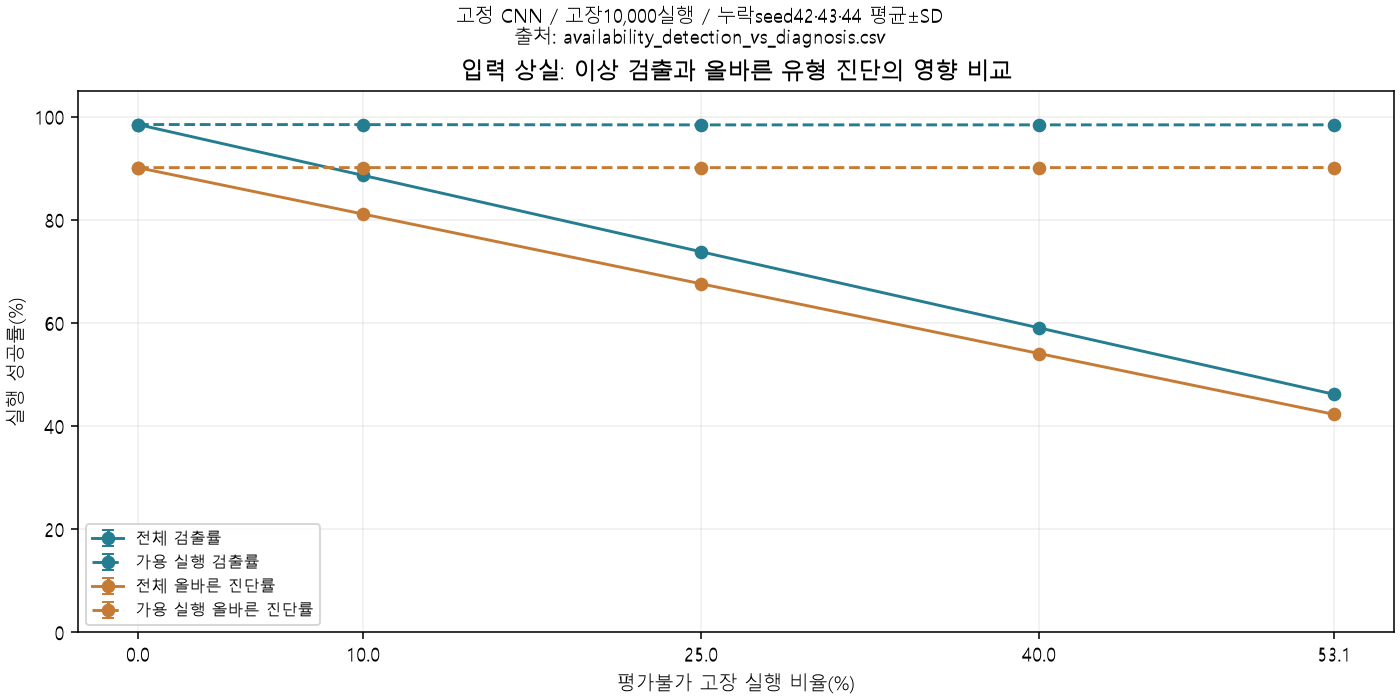

In [7]:
show('availability',['rate','available_runs','unavailable_runs','overall_detection_rate',
 'conditional_detection_rate','overall_correct_diagnosis_rate','conditional_correct_diagnosis_rate'])
picture('availability')

53.1% 조건의 전체 검출률46.17%, 전체 정답 진단률42.29%와 달리, 가용 실행의 조건부 성능은 약98.45%,90.16%입니다. **모델의 분류 능력 저하를 직접 보인 결과가 아니라, 입력 상실로 적용 범위가 줄어드는 효과**입니다.

## 6. TEP — 별도 LSTM 공정 변수 예측

이 LSTM은 앞의 21종 LSTM 분류기와 다릅니다. 정상 Train400실행으로20×52→다음3분52변수를 학습했습니다. 2층hidden64, 현재값+예측 변화량 구조이며, seed42/7/2026을 비교했습니다. Validation으로 epoch를 선택하고 대표seed42의 전체9,870,000개 정답 시점을 평가했습니다. CNN에 연결하거나 결측 복원에 쓰지 않았습니다.

정상 Train 표준편차로 정규화한 오차입니다. 전체 RMSE는 개선됐지만 MAE는 악화됐으므로 전반적으로 항상 더 좋은 예측기라고 말할 수 없습니다.

seed,epoch,validation_normalized_mse,persistence_validation_mse,train_windows,validation_windows,training_seconds,device
42,12,0.575698,0.995008,48000,48000,14.073343,cuda
7,12,0.572294,0.995008,48000,48000,12.986929,cuda
2026,12,0.576422,0.995008,48000,48000,11.660936,cuda


model,cohort,target_rows,normalized_rmse,normalized_mae
LSTM,all,9870000,1.494316,0.737834
LSTM,healthy_context,1870000,0.757800,0.533813
LSTM,post_fault,8000000,1.618859,0.785524
LSTM,faultfree_only,470000,0.758061,0.534008
Persistence,all,9870000,1.630137,0.690530
Persistence,healthy_context,1870000,0.996301,0.636533
Persistence,post_fault,8000000,1.745416,0.703152
Persistence,faultfree_only,470000,0.996280,0.636685


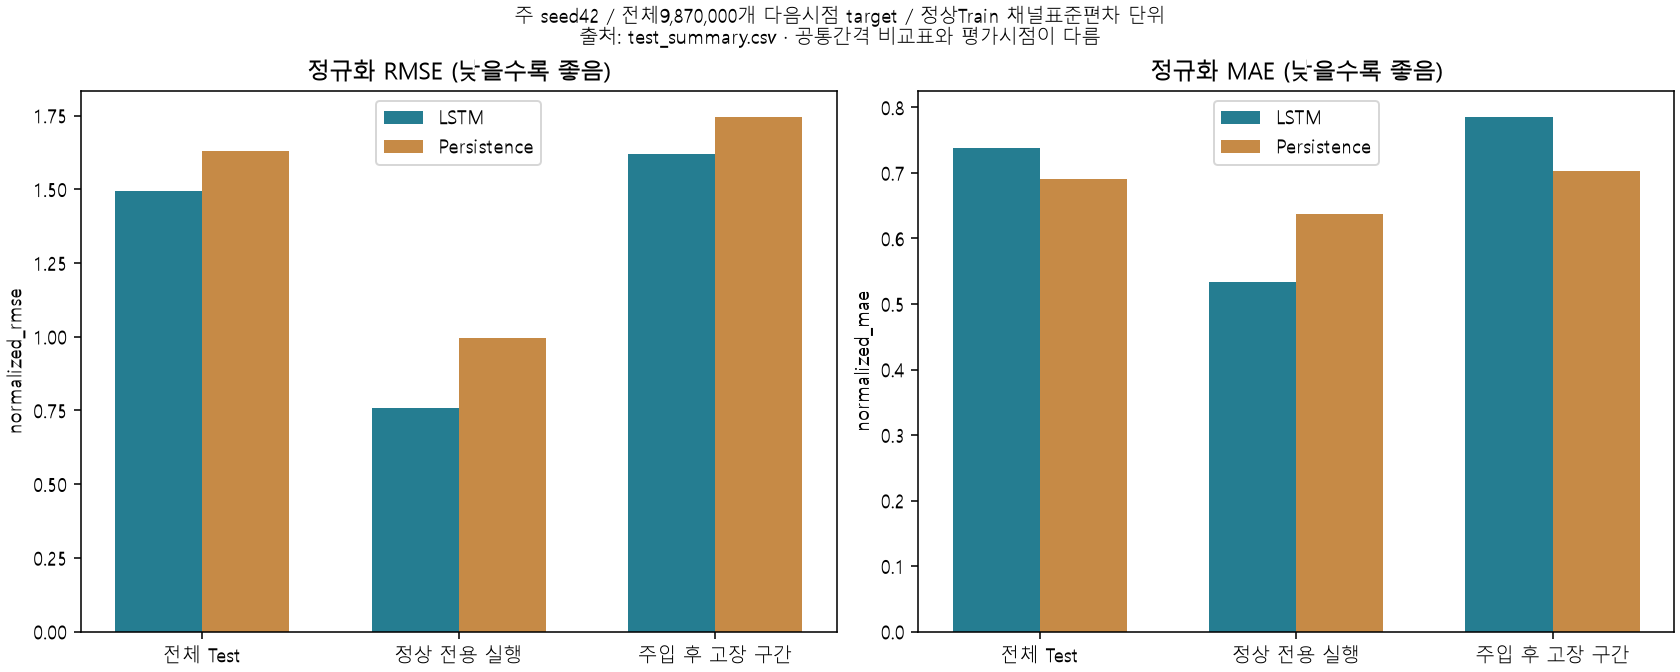

In [8]:
show('forecast_train')
f=T['forecast_test'];display(f[(f.seed==42)&(f['mode']=='dense')][['model','cohort','target_rows','normalized_rmse','normalized_mae']].style.hide(axis='index'))
picture('forecast')

## 7. PHM V1 — 최초 모델 비교

Dummy·압력 임계값·Random Forest·XGBoost를 비교했습니다. A8=현재 센서6개+recipe/stage, B80=현재+과거60/300통계, C83=공정 전환 등 추가입니다. 이는 **V3의 A8/B32/C44와 다른 정의**입니다.

horizon300/600/1800, 장비 분할·시간 분할, A/B/C를 비교한48실험과 Tool/time/Lot/사용량을 넣어 의존성을 보는10진단 실험을 보존했습니다. ID 진단 모델은 주 모델과 분리합니다. 알려진 라벨·충분한 이력이 있는 관측만의 결과이며 미확인 라벨을 정상으로 바꾸지 않았습니다.

scheme,name,config,n,positive,accuracy,f1,pr_auc_ap,roc_auc,event_recall
split_time,Dummy,none,10365,475,0.9542,0.0000,0.0458,0.5000,0.0000
split_time,Pressure,pressure,10365,475,0.9542,0.0000,0.2006,0.5679,0.0000
split_time,RF_A,A,10365,475,0.9591,0.2030,0.2671,0.7145,0.1071
split_time,RF_B,B,10365,475,0.9515,0.2153,0.1912,0.6367,0.1786
split_time,RF_C,C,10365,475,0.9562,0.1715,0.1793,0.6360,0.1429
split_time,XGB_A,A,10365,475,0.9658,0.4054,0.3151,0.7059,0.3750
split_time,XGB_B,B,10365,475,0.9606,0.3038,0.2925,0.6675,0.3393
split_time,XGB_C,C,10365,475,0.9603,0.2648,0.2788,0.6437,0.3036
split_tool,Dummy,none,30470,345,0.9887,0.0000,0.0113,0.5000,0.0000
split_tool,Pressure,pressure,30470,345,0.7071,0.0272,0.0136,0.5187,0.3778


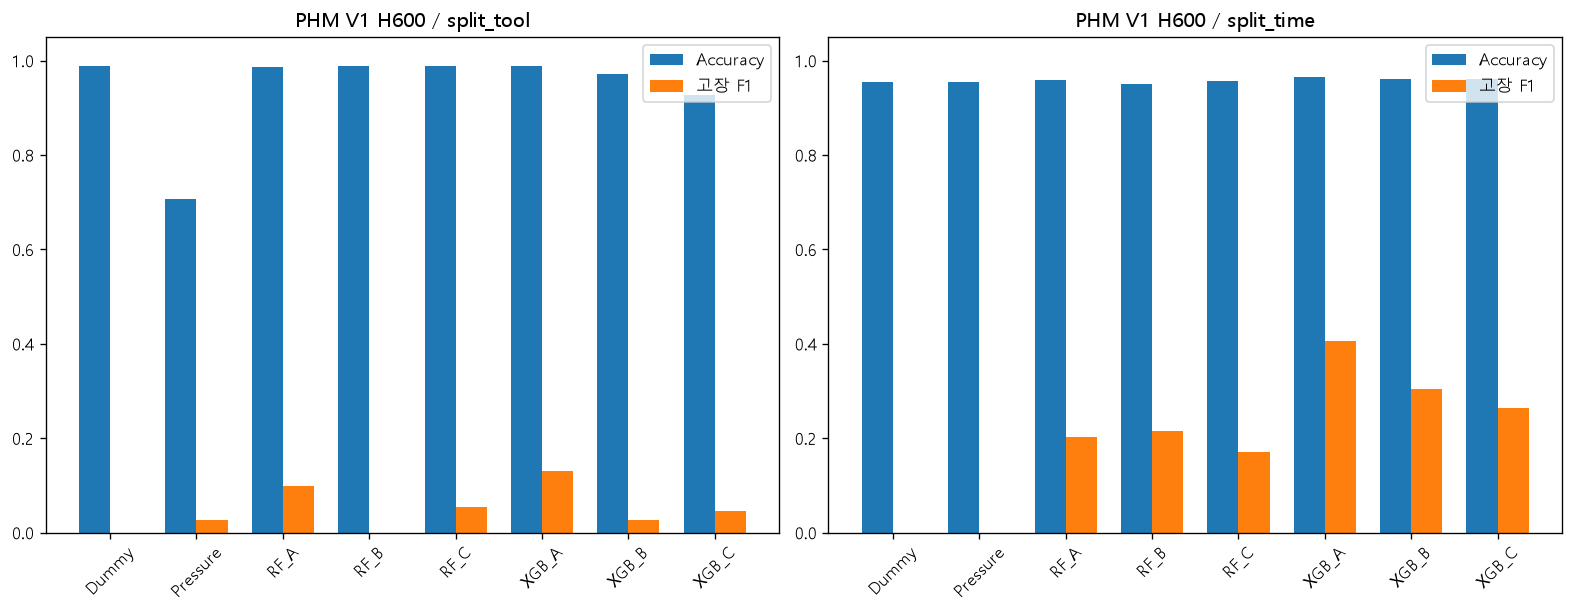

In [9]:
m=T['v1_metrics'];main=m[(m.split=='evaluation')&(m.horizon==600)&(~m.identity_diagnostic)]
display(main[['scheme','name','config','n','positive','accuracy','f1','pr_auc_ap','roc_auc','event_recall']].style.format(precision=4).hide(axis='index'))
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for ax,scheme in zip(axes,['split_tool','split_time']):
 g=main[main.scheme==scheme];x=np.arange(len(g))
 ax.bar(x-.18,g.accuracy,.36,label='Accuracy');ax.bar(x+.18,g.f1,.36,label='고장 F1')
 ax.set(xticks=x,xticklabels=g.name,ylim=(0,1.05),title=f'PHM V1 H600 / {scheme}')
 ax.tick_params(axis='x',rotation=45);ax.legend()
plt.show()

**Accuracy가 높아도 고장을 잘 찾는 것은 아닙니다.** 양성이 적은 PHM에서 항상 정상으로 판단하는 Dummy도 높은 Accuracy가 나올 수 있습니다. F1·AP·이벤트 검출과 함께 읽어야 합니다. 아래는 당시 Validation AP로 선정한 대표 모델의 실제 평가 결과이며, 현재 표를 보고 새로 선택한 모델이 아닙니다.

In [10]:
selected=pd.DataFrame(E['v1_summary']['selected_per_family'])
selected['accuracy']=(selected.tp+selected.tn)/(selected.tp+selected.tn+selected.fp+selected.fn)
display(selected[['scheme','selected_by_validation_AP','accuracy','f1','pr_auc_ap','roc_auc','tp','fn']].style.format(precision=4).hide(axis='index'))
display(m[m.split=='evaluation'][['scheme','horizon','name','config','identity_diagnostic','accuracy','f1','pr_auc_ap','event_recall']].style.format(precision=4).hide(axis='index'))

scheme,selected_by_validation_AP,accuracy,f1,pr_auc_ap,roc_auc,tp,fn
split_tool,RF_A,0.9856,0.0988,0.0471,0.5838,24,321
split_tool,XGB_A,0.9895,0.1301,0.0852,0.4574,24,321
split_time,RF_B,0.9515,0.2153,0.1912,0.6367,69,406
split_time,XGB_C,0.9603,0.2648,0.2788,0.6437,74,401


scheme,horizon,name,config,identity_diagnostic,accuracy,f1,pr_auc_ap,event_recall
split_time,1800,Dummy,none,False,0.7767,0.0000,0.2233,0.0000
split_time,1800,Pressure,pressure,False,0.6993,0.2579,0.3834,0.3571
split_time,1800,RF_A,A,False,0.7910,0.1697,0.5195,0.2500
split_time,1800,RF_B,B,False,0.7786,0.1355,0.3521,0.3750
split_time,1800,RF_C,C,False,0.7924,0.1830,0.4159,0.3393
split_time,1800,XGB_A,A,False,0.8000,0.1887,0.5315,0.1429
split_time,1800,XGB_B,B,False,0.8200,0.3472,0.4846,0.4821
split_time,1800,XGB_C,C,False,0.8294,0.3981,0.5102,0.5000
split_time,300,Dummy,none,False,0.9819,0.0000,0.0181,0.0000
split_time,300,Pressure,pressure,False,0.9819,0.0000,0.1607,0.0000


## 8. PHM V1 — 4.5단계 장비 일반화 개선 실험

개발 장비의4-Fold × A/B/C/C_regularized로 XGBoost16개를 학습했습니다. 각 모델에 F1정책과 이벤트/FAR정책 두 경보 방식을 평가하여 성능표는32행입니다. 정책 수를 학습 수로 세지 않습니다. 학습·조기 종료·임계값 보정·외부 Fold의 장비를 분리했고, 기존 평가09/10계열은 새 학습·선택에서 제외했습니다.

결론은 **일반화 개선이 확실히 입증되지 않음**입니다. 기존 데이터의 후향적 후속 분석이며 새로운 미관측 외부 검증 결과가 아닙니다.

In [11]:
cv=T['v1_cv'];agg=cv.groupby(['model','policy']).agg(
 accuracy_mean=('accuracy','mean'),accuracy_sd=('accuracy','std'),f1_mean=('f1','mean'),
 AP_mean=('pr_auc_ap','mean'),event_recall_mean=('event_recall','mean')).reset_index()
display(agg.style.format(precision=4).hide(axis='index'))
show('v1_cv_means',['model','policy','f1_mean','event_recall_mean','false_alarms_per_active_hour_mean'])

model,policy,accuracy_mean,accuracy_sd,f1_mean,AP_mean,event_recall_mean
A,event_far,0.8816,0.2312,0.0035,0.0123,0.0788
A,f1,0.7970,0.2488,0.0049,0.0123,0.2672
B,event_far,0.9875,0.0164,0.0172,0.0093,0.0884
B,f1,0.7171,0.4784,0.0219,0.0093,0.4070
C,event_far,0.9897,0.0122,0.0175,0.0095,0.0884
C,f1,0.7377,0.4901,0.0222,0.0095,0.3549
C_regularized,event_far,0.9345,0.1166,0.0208,0.0059,0.1746
C_regularized,f1,0.5596,0.4140,0.0181,0.0059,0.4571


model,policy,f1_mean,event_recall_mean,false_alarms_per_active_hour_mean
A,event_far,0.003465,0.078793,0.799327
A,f1,0.004880,0.267183,1.487565
B,event_far,0.017228,0.088390,0.143208
B,f1,0.021925,0.407010,1.617664
C,event_far,0.017457,0.088390,0.142571
C,f1,0.022202,0.354871,1.539215
C_regularized,event_far,0.020770,0.174613,0.756848
C_regularized,f1,0.018097,0.457137,2.993185


## 9. PHM V2 — 모델 성능을 제시하지 않는 이유

V2는 전체20대 원본 감사와 대표2대 후보 특징·라벨·분할 진단 단계입니다. 시간 단위·고장 이력 완전성·정비 종료가 확정되지 않아 정식 학습 데이터 배포와 모델 학습을 차단했습니다. A8/B32/C44 후보가 있다는 것은 모델이 학습됐다는 뜻이 아닙니다. Accuracy·F1은 **미산출**입니다. V1 재분석 폴더도 모델 재학습 결과가 확인되지 않아 별도 모델로 세지 않았습니다.

## 10. PHM V3 — 실제로 학습한 모델과 단계

센서6개+recipe/stage의 A8, 과거300raw mean/std/min/max를 더한 B32, 추가 공정 이력을 더한 C44를 비교했습니다. 수치 표준화·범주형 One-Hot은 Train에서만 fit했습니다. 범주형 인코딩 후 열 수는 학습 집합마다 달라집니다. 시간/장비ID/TTF/미래 라벨은 입력에서 제외했습니다.

stage2는 각 특징의 최대가용 입력, stage3는 A/B/C가 모두 가능한 동일 공통 입력입니다. 분모가 다르므로 stage2와3의 점수 차이를 특징 개선으로 단정하지 않습니다. 알려진 라벨 AP/ROC-AUC는 보조 분류 지표이고, NA/EXCLUDE까지 점수화한 이벤트 검출과 경보 부담을 함께 봅니다.

**stage2: 최대가용 코호트 4개**

run_id,feature_set,model,train_rows,validation_known_rows,encoded_features,iterations,AP_known,ROC_AUC_known,train_seconds
A_logistic,A,logistic,916051,25266,424,94,0.058390,0.376102,2.758614
A_xgboost,A,xgboost,916051,25266,424,27,0.170344,0.439372,0.680361
B_logistic,B,logistic,664285,17398,446,130,0.070042,0.394552,5.354463
B_xgboost,B,xgboost,664285,17398,446,2,0.067437,0.468656,1.236616


**stage3: 공통 코호트 6개**

run_id,feature_set,model,train_rows,validation_known_rows,encoded_features,iterations,AP_known,ROC_AUC_known,train_seconds
A_logistic,A,logistic,309273,7158,233,77,0.104289,0.268809,0.918014
A_xgboost,A,xgboost,309273,7158,233,53,0.245622,0.585560,0.498086
B_logistic,B,logistic,309273,7158,257,126,0.102549,0.283926,2.557342
B_xgboost,B,xgboost,309273,7158,257,36,0.206897,0.513422,0.930693
C_logistic,C,logistic,309273,7158,269,151,0.102989,0.297317,3.616388
C_xgboost,C,xgboost,309273,7158,269,14,0.195928,0.543356,0.984156


run_id,recorded_events,available_events,detected_events,recall_recorded,recall_available,alarm_episodes_per_10000_raw
A_logistic,232.0000,53.0000,12.0000,0.0517,0.2264,8.8277
A_xgboost,232.0000,53.0000,17.0000,0.0733,0.3208,6.1357
B_logistic,232.0000,53.0000,12.0000,0.0517,0.2264,9.0620
B_xgboost,232.0000,53.0000,13.0000,0.0560,0.2453,4.4696
C_logistic,232.0000,53.0000,12.0000,0.0517,0.2264,8.9258
C_xgboost,232.0000,53.0000,12.0000,0.0517,0.2264,8.7750


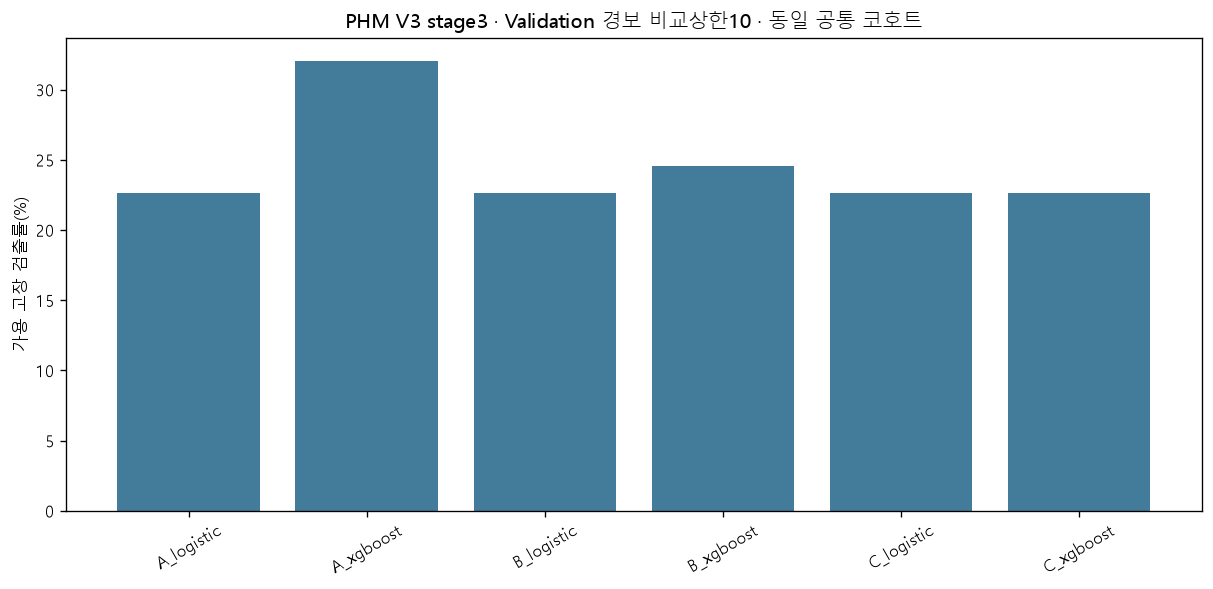

In [12]:
cols=['run_id','feature_set','model','train_rows','validation_known_rows','encoded_features','iterations','AP_known','ROC_AUC_known','train_seconds']
display(Markdown('**stage2: 최대가용 코호트 4개**'));show('phm_stage2_train',cols)
display(Markdown('**stage3: 공통 코호트 6개**'));show('phm_stage3_train',cols)
points=T['phm_stage3_points'];p=points[points.budget_per_10000_raw==10]
display(p[['run_id','recorded_events','available_events','detected_events','recall_recorded','recall_available','alarm_episodes_per_10000_raw']].style.format(precision=4).hide(axis='index'))
fig,ax=plt.subplots(figsize=(10,4.8),layout='constrained')
ax.bar(p.run_id,p.recall_available*100,color='#427c9a')
ax.set(ylabel='가용 고장 검출률(%)',title='PHM V3 stage3 · Validation 경보 비교상한10 · 동일 공통 코호트')
ax.tick_params(axis='x',rotation=30);plt.show()

### stage4: 제한 튜닝·seed 민감도

A/B의 depth·양성 가중치를 비교하고 설정을 동결한 뒤 seed43/44를 확인했습니다. 18개 신규 학습과3개 기존 실행 재사용으로21행입니다. seed42에서의 개선이 다른seed에서 일관되지 않아 기존 기준을 유지했습니다. 아래 AP/ROC-AUC는 동일 Validation 기반이며 최종 Holdout 성능이 아닙니다. 임계값 고정 이전과 seed별 재선택도 분리해 보존했습니다.

In [13]:
show('phm_stage4_train',['run_id','feature_set','depth','weight_mode','seed','reused_stage3','phase','iterations','AP_known','ROC_AUC_known'])
show('phm_stage4_ranges')

run_id,feature_set,depth,weight_mode,seed,reused_stage3,phase,iterations,AP_known,ROC_AUC_known
A_d2_unit_s42,A,2,unit,42,False,grid,68,0.311415,0.549518
A_d2_sqrt_train_neg_pos_s42,A,2,sqrt_train_neg_pos,42,False,grid,102,0.352697,0.627713
A_d3_unit_s42,A,3,unit,42,True,grid,53,0.245622,0.585560
A_d3_sqrt_train_neg_pos_s42,A,3,sqrt_train_neg_pos,42,False,grid,47,0.381319,0.726525
A_d4_unit_s42,A,4,unit,42,False,grid,6,0.256085,0.553900
A_d4_sqrt_train_neg_pos_s42,A,4,sqrt_train_neg_pos,42,False,grid,1,0.259144,0.684313
B_d2_unit_s42,B,2,unit,42,False,grid,13,0.206229,0.488094
B_d2_sqrt_train_neg_pos_s42,B,2,sqrt_train_neg_pos,42,False,grid,54,0.374046,0.566335
B_d3_unit_s42,B,3,unit,42,True,grid,36,0.206897,0.513422
B_d3_sqrt_train_neg_pos_s42,B,3,sqrt_train_neg_pos,42,False,grid,2,0.337706,0.533104


mode,config_id,budget_per_10000_raw,detected_min,detected_max,detected_mean,burden_min,burden_max,exceeding_seeds
retuned,A_d2_sqrt_train_neg_pos,0.500000,1.000000,1.000000,1.000000,0.001121,0.009530,0
retuned,A_d2_sqrt_train_neg_pos,5.000000,4.000000,10.000000,7.666667,2.346088,4.342926,0
retuned,A_d2_sqrt_train_neg_pos,10.000000,15.000000,21.000000,17.666667,5.997800,8.854029,0
retuned,A_d2_sqrt_train_neg_pos,20.000000,17.000000,21.000000,19.333333,6.604364,10.864321,0
retuned,A_d3_unit,0.500000,0.000000,2.000000,1.000000,0.000000,0.361023,0
retuned,A_d3_unit,5.000000,7.000000,10.000000,8.666667,2.297316,4.022265,0
retuned,A_d3_unit,10.000000,17.000000,19.000000,18.333333,5.928287,6.403110,0
retuned,A_d3_unit,20.000000,19.000000,19.000000,19.000000,5.928287,11.445658,0
retuned,B_d3_unit,0.500000,3.000000,8.000000,5.000000,0.206859,0.455763,0
retuned,B_d3_unit,5.000000,8.000000,13.000000,10.333333,0.455763,4.469620,0


### stage5: 장비 그룹 검증

01–06학습 /07–08검증, 기존 시간 Holdout을 제외한6개 XGBoost를 학습했습니다. 최대가용 A/B와 공통A/B/조정A/C입니다. 시간 Validation·그룹 Validation을 함께 고려해 사전 규칙으로 최종 B를 선택했습니다. 이 그룹 모델을 최종 모델로 교체한 것이 아니라 **기존 stage2 B를 최종 모델로 동결**했습니다.

run_id,cohort,train_rows,validation_known_rows,iterations,AP_known,ROC_AUC_known
A_base_maximum,maximum,588409,321168,10,0.001622,0.548903
B_base_maximum,maximum,446724,213592,49,0.005288,0.512233
A_base_common,common,246923,62704,98,0.094469,0.586055
B_base_common,common,246923,62704,28,0.041373,0.521478
A_tuned_common,common,246923,62704,24,0.013671,0.557121
C_base_common,common,246923,62704,56,0.041440,0.511810


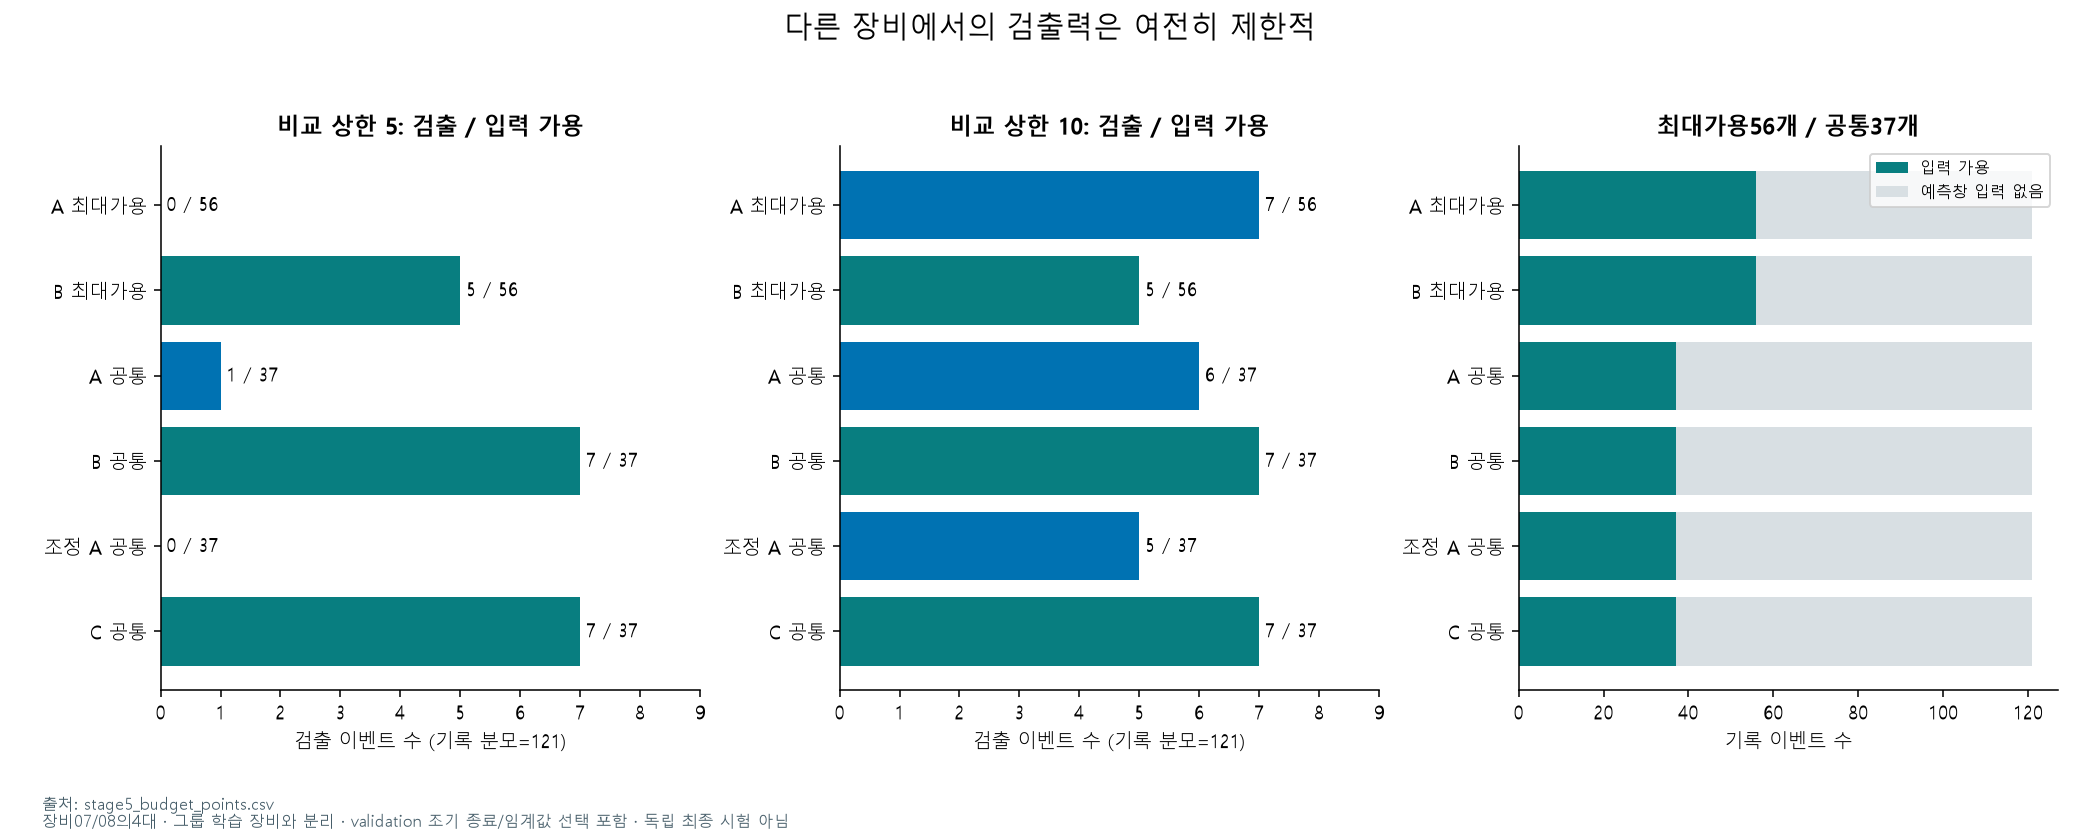

In [14]:
show('phm_stage5_train',['run_id','cohort','train_rows','validation_known_rows','iterations','AP_known','ROC_AUC_known'])
picture('phm_group')

## 11. PHM V3 — 최종 동결 모델과 Holdout

최종 artifact는 stage2의 B XGBoost(seed42, depth3, 선택tree2)와 Train 전용 전처리입니다. train+validation 재학습 없이 모델과 두 임계값을 동결했습니다. 각 장비 마지막20%를 한 번 추론한 뒤 저장 예측만 재사용했습니다.

고장 전 `[t_fault-600, t_fault-60]` raw 구간에 시작한 유효 경보를 평가합니다. 기록194개 중91개만 입력이 있었고103개는 평가 불가능했습니다. 아래 두 운영점은 모두 사전에 동결됐으며 최종 결과를 보고 재선택하지 않았습니다.

operating_point,threshold,recorded_events,available_events,detected_events,recall_recorded,recall_available,alarm_episodes,alarm_episodes_per_10000_raw,median_lead_raw
validation_budget_5,0.003267,194.000000,91.000000,7.000000,0.036082,0.076923,3389.000000,0.814981,284.000000
validation_budget_10,0.002999,194.000000,91.000000,33.000000,0.170103,0.362637,41162.000000,9.898565,362.000000


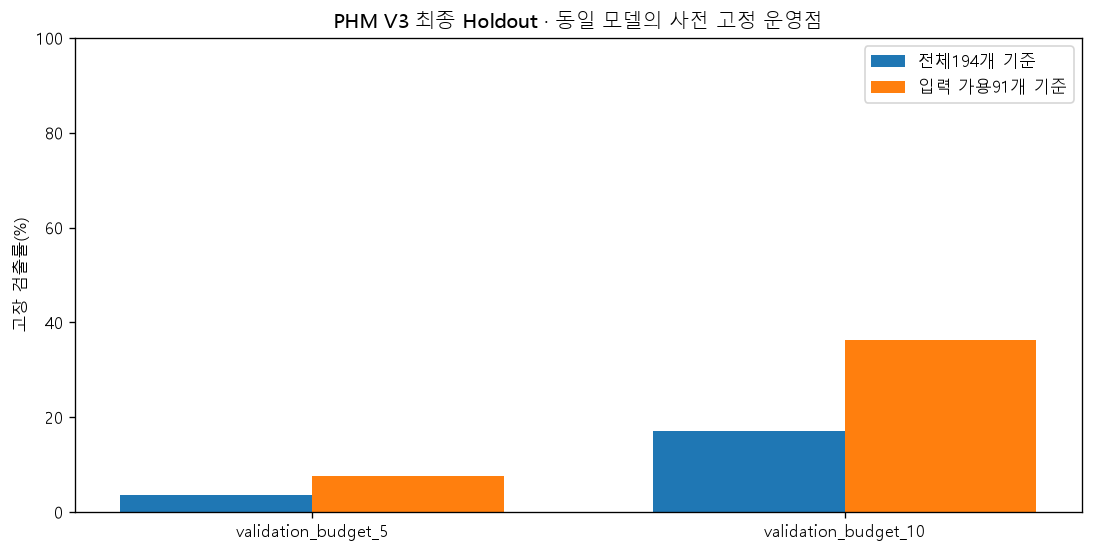

In [15]:
show('phm_holdout',['operating_point','threshold','recorded_events','available_events','detected_events',
 'recall_recorded','recall_available','alarm_episodes','alarm_episodes_per_10000_raw','median_lead_raw'])
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
q=T['phm_holdout'];x=np.arange(len(q))
ax.bar(x-.18,q.recall_recorded*100,.36,label='전체194개 기준')
ax.bar(x+.18,q.recall_available*100,.36,label='입력 가용91개 기준')
ax.set(xticks=x,xticklabels=q.operating_point,ylabel='고장 검출률(%)',ylim=(0,100),title='PHM V3 최종 Holdout · 동일 모델의 사전 고정 운영점')
ax.legend();plt.show()

### PHM 최종 모델의 Accuracy도 계산할 수 있나?

저장된 Holdout 예측의 `audit_label`이0/1인 **정답 확인32,645개 시점**에서 고정 임계값별 Accuracy를 추가 계산했습니다. 나머지 미확인/제외 입력을 임의 정상으로 바꾸지 않았습니다. 이는 입력736,646개 전체의 Accuracy나 고장194개 전체의 검출률이 아닙니다. 아래의 ‘항상 정상 Accuracy’는 라벨 불균형을 보여주는 **학습 없는 계산 기준**입니다.

고정 모델의 알려진 라벨 AP=0.0654, ROC-AUC=0.5012였습니다. 높은 Accuracy가 나오더라도 실제 고장 조기 예측이 충분하다는 뜻은 아닙니다.

In [16]:
acc=T['phm_holdout_accuracy'].copy();acc['always_normal_accuracy']=acc.negative/acc.known_rows
display(acc.style.format({'accuracy':'{:.2%}','always_normal_accuracy':'{:.2%}','recall':'{:.2%}','precision':'{:.2%}'}).hide(axis='index'))
display(pd.DataFrame([E['phm_classification']]).drop(columns=['label_counts']).style.hide(axis='index'))

operating_point,threshold,all_input_rows,known_rows,positive,negative,tp,tn,fp,fn,accuracy,recall,precision,always_normal_accuracy
validation_budget_5,0.003267,736646,32645,635,32010,113,30082,1928,522,92.50%,17.80%,5.54%,98.05%
validation_budget_10,0.002999,736646,32645,635,32010,435,4371,27639,200,14.72%,68.50%,1.55%,98.05%


all_anchors,known_anchors,positive,AP_known,ROC_AUC_known,log_loss_known
736646,32645,635,0.065410,0.501175,0.114813


## 12. PHM V3 — 장비 전용 모델 후속 파일럿

최대3대 후보 중 최소 학습/검증 조건을 통과한03M02 한 대에만 B XGBoost를 학습했습니다. 전용 모델과 공통 모델의 장비별 임계값 조정, 공통 모델 기존 임계값을 비교했습니다.

후반 구간은 이미 본 데이터를 다시 사용한 연구 비교로 독립 최종 Holdout이 아닙니다. 27개 고장 중24개는 입력이 없고3개만 가용했습니다. 전용 모델은0개를 검출했습니다. 공통 모델 기존 높은 경보 설정은2개를 검출했지만 경보 부담이 더 크므로 동일 부담에서의 우위를 주장하지 않습니다.

Tool,device,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,iterations,train_seconds,AP_known,ROC_AUC_known,log_loss_known
03M02,cuda:0,123796,500,41467,6115,133,1,0.518429,0.034911,0.548815,0.123639


장비,방식,검증 비교상한,동결 임계값,검출,기록 고장,입력 가용 고장,전체 경보,경보/10000 raw,미확인 시작 경보
03M02,장비 전용,5,0.004388,0,27,3,228,0.853399,228
03M02,장비 전용,10,0.004241,0,27,3,289,1.081721,289
03M02,공통·장비별 임계값,5,0.003267,0,27,3,141,0.527760,141
03M02,공통·장비별 임계값,10,0.003267,0,27,3,141,0.527760,141
03M02,공통·기존 임계값,5,0.003267,0,27,3,141,0.527760,141
03M02,공통·기존 임계값,10,0.002999,2,27,3,5411,20.253265,5409


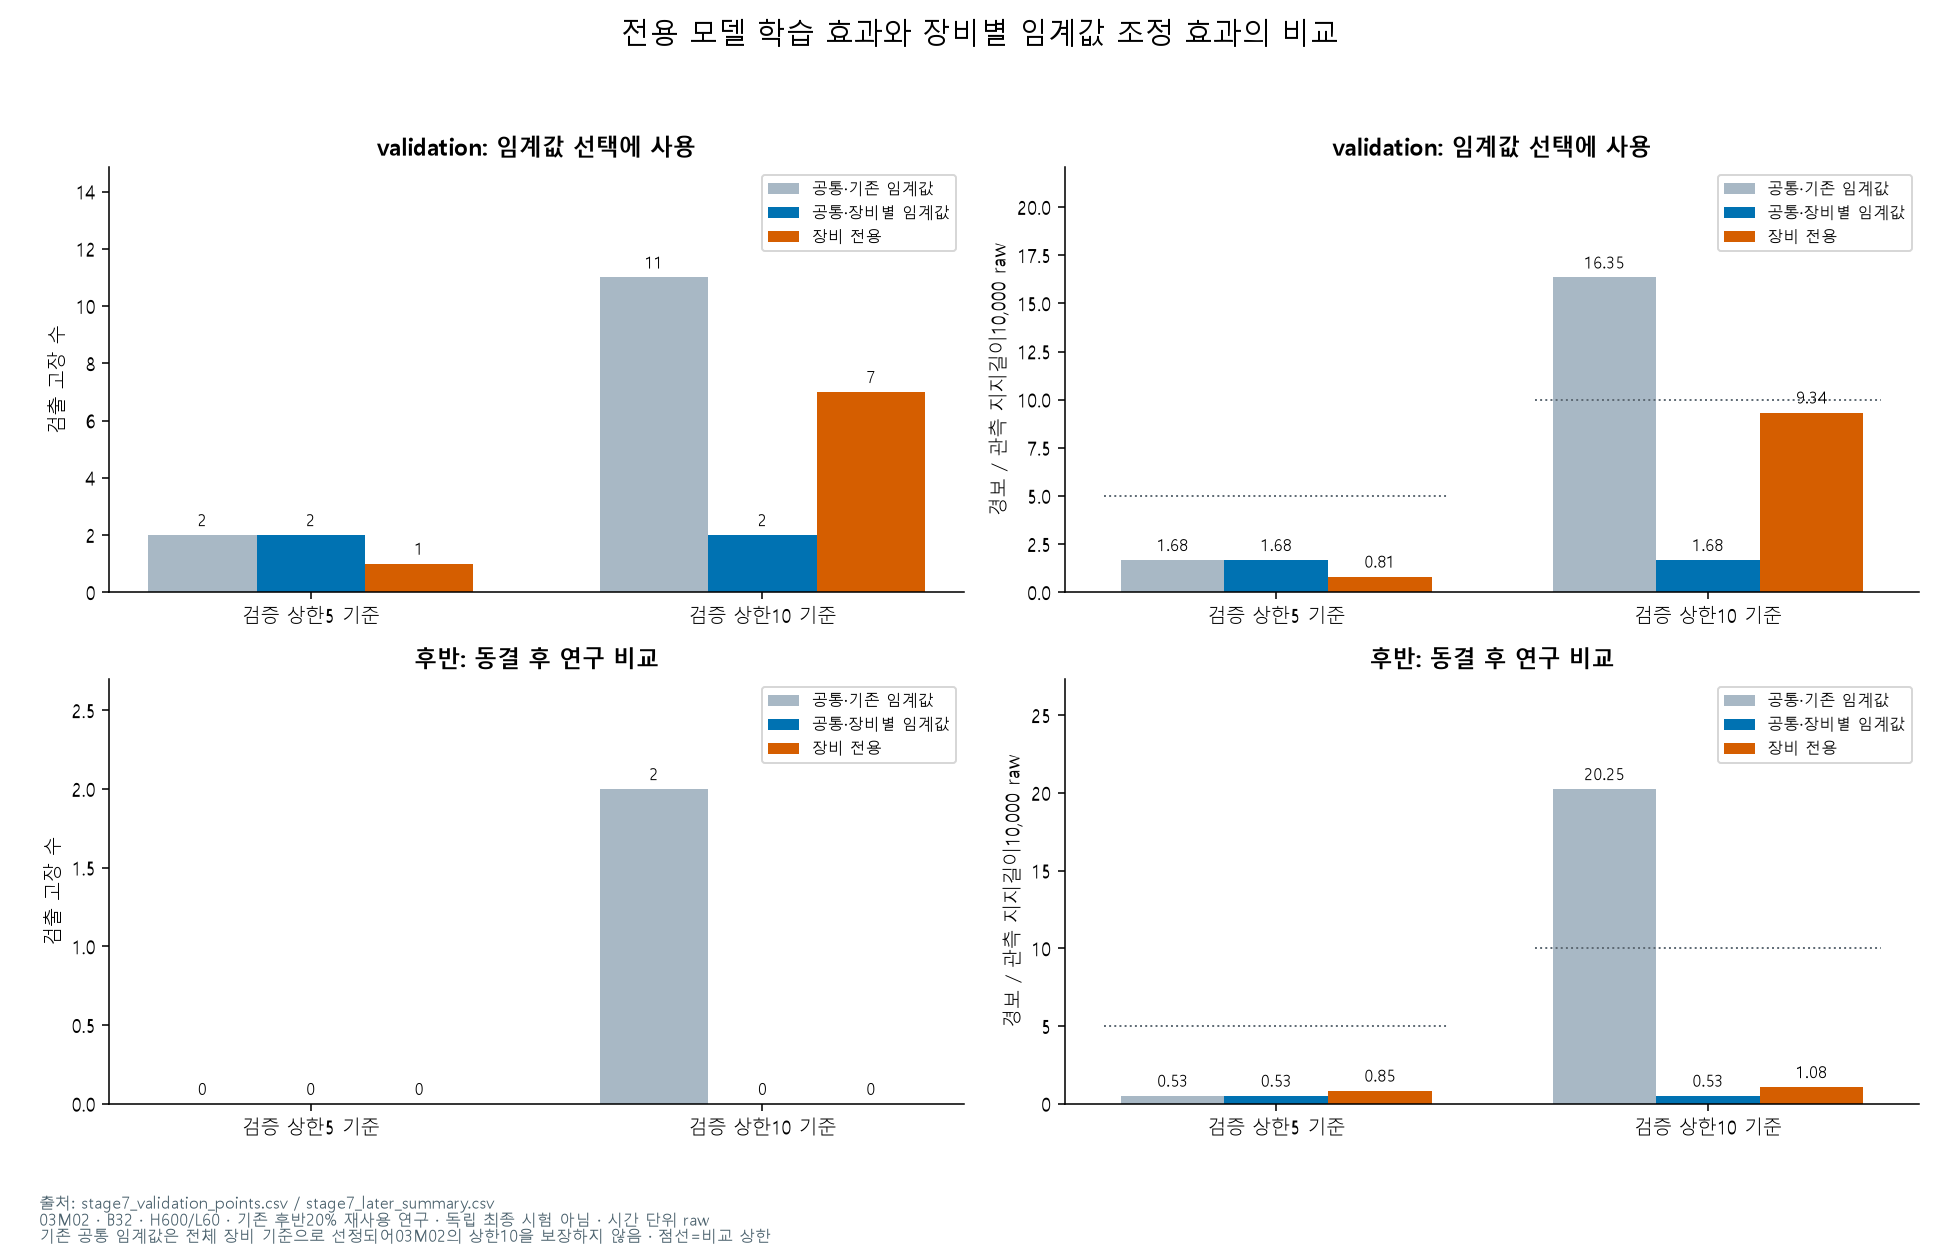

In [17]:
show('phm_stage7_train')
show('phm_specialist')
picture('phm_specialist')

## 13. TEP와 PHM에서 배운 차이

| 항목 | TEP | PHM2018 V3 |
|---|---|---|
| 목적 | 주입 후 검출·유형 진단 | 정지 이벤트 이전 조기 예측 |
| 데이터 | 규칙적3분 간격 시뮬레이션52변수 | 실제 장비 센서·공정, 공백·라벨 미확인 존재 |
| 최종 주 모델 | 1D-CNN 21클래스 | B XGBoost 이진 위험점수 |
| 사건 단위 | 고장 실행10,000개 | 기록 고장194개 |
| 원본 평가 입력 가용성 | 모든 실행에 고장 이후 유효 입력 | 91개 가용 /103개 불가 |
| 입력53.1% 손실 비교 | 전체 검출46.17%, 조건부98.45% | 전체17.01%, 조건부36.26% (고정 상한10 운영점) |
| 해석 | 적용 범위 손실과 유형 혼동 분리 | 입력·라벨·공정 분포·장비 일반화 제약 |

표의 검출률은 같은 과제의 우열 비교가 아닙니다. PHM의 실제 pre-fault 입력조건과 TEP의20시점 창 조건도 다릅니다. TEP에서는 ‘기회가0이면 평가 불가’라는 의미를 모사했습니다.

실행이 입력 불가하면 모델 교체만으로 해결되지 않습니다. 입력이 있어도 검출/정답 진단에 실패할 수 있으므로 전체와 조건부 성공률을 함께 봐야 합니다. 학습하지 않은 기준선·튜닝 변형·평가 후속 분석을 새로운 모델 성능 향상으로 표현하지 않았습니다.

## 14. TEP 모든 평가 모델 — 전체 기록

아래는 seed·가중치 후보와 Binary/Unknown 실험을 포함한44개 model_id입니다. Accuracy는 저장된 혼동행렬로 계산했고, 별도 이진 모델은 저장 recall/FAR와 공통 평가의 양성800,000·음성197,500으로 계산했습니다. Unknown 모델의 아래 전체 성능에는 기지·미지 고장이 섞이므로 미지 성능은4절을 확인합니다.

In [18]:
show('tep_all_results',['model_id','samples','binary_accuracy','class21_accuracy','detection_f1',
 'diagnosis_macro_f1','end_to_end_macro_f1','detection_roc_auc'])

model_id,samples,binary_accuracy,class21_accuracy,detection_f1,diagnosis_macro_f1,end_to_end_macro_f1,detection_roc_auc
LogisticRegression_Current_natural_s42,997500,0.646538,0.567113,0.718295,0.516140,0.470851,0.791819
LogisticRegression_Current_balanced_s42,997500,0.640170,0.564295,0.711840,0.514561,0.469073,0.789700
LogisticRegression_Current_natural_s7,997500,0.646538,0.567113,0.718295,0.516140,0.470851,0.791819
LogisticRegression_Current_natural_s2026,997500,0.646538,0.567113,0.718295,0.516140,0.470851,0.791819
LogisticRegression_Statistical_natural_s42,997500,0.843202,0.816056,0.891893,0.856258,0.787037,0.935498
LogisticRegression_Statistical_balanced_s42,997500,0.843201,0.816042,0.891907,0.855969,0.787105,0.935162
LogisticRegression_Statistical_balanced_s7,997500,0.843201,0.816042,0.891907,0.855969,0.787105,0.935162
LogisticRegression_Statistical_balanced_s2026,997500,0.843201,0.816042,0.891907,0.855969,0.787105,0.935162
RandomForest_Current_natural_s42,997500,0.730778,0.694098,0.798921,0.740792,0.659884,0.894540
RandomForest_Current_balanced_s42,997500,0.733643,0.696824,0.801403,0.737453,0.663771,0.894699


## 15. 자료 위치와 재확인 방법

| 자료 | 위치 |
|---|---|
| TEP 기능 확장 안내 | `TEP/notebooks/17_CNN_기능확장_종합안내.ipynb` |
| TEP 모든 model_id 원 평가 | `TEP/reports/tables/phase2/test_comparison.csv` |
| PHM V1 최초 모델 비교 | `PHM2018-Project/reports/04_model_training_summary.md` |
| PHM V1 4-Fold 개선 | `PHM2018-Project/reports/04_5_model_improvement_summary.md` |
| PHM V2 학습 전 진단 | `PHM2018-Project-V2/README.md` |
| PHM 전체 기존 수행 결과 | `PHM2018-Project-V3/notebooks/00_PHM2018_종합_수행결과.ipynb` |
| PHM 최종 모델·평가 | `PHM2018-Project-V3/reports/19_group_and_holdout.md` |
| PHM 장비 전용 후속 | `PHM2018-Project-V3/reports/20_equipment_specialists.md` |
| 이번 내장 자료 CSV | `TEP/reports/all_models/tables/` |
| 이번 자료 해시·출처 | `TEP/reports/all_models/source_manifest.json` |

노트북의 `T` 사전에서 원 평가표를 다시 확인할 수 있습니다. 예를 들어 `T['tep_all_results']`는 TEP 전체 모델, `T['v1_metrics']`는 V1 전체 분할 결과, `T['phm_stage4_train']`은 V3 튜닝 실행입니다. 원본 결과를 바꾸거나 새 학습을 시작할 필요가 없습니다.

공란은 미산출/해당 없음입니다. PHM 미확인 시작 경보는 확정 오경보가 아니며, raw당 전체 경보 부담을 TEP 정상 시간당 오경보와 직접 비교하지 않습니다. 이 노트북은 로컬에서 확인된 실험을 정리한 것이며 별도의 외부 검증이나 배포 검증을 추가하지 않았습니다.

In [19]:
assert len(T['tep_all_results'])==44
assert len(T['v1_metrics'].query("split == 'evaluation'"))==58
assert len(T['phm_stage4_train'])==21
assert (~T['phm_stage4_train'].reused_stage3).sum()==18
assert (T['phm_holdout_accuracy'].known_rows==32645).all()
assert (T['phm_holdout'].recorded_events-T['phm_holdout'].available_events==103).all()
display(Markdown('**내장 표의 실험 수·재사용 수·PHM 라벨 분모·입력 불가 수 검증 통과.**'))

**내장 표의 실험 수·재사용 수·PHM 라벨 분모·입력 불가 수 검증 통과.**